# Caso práctico: limpieza y preprocesamiento de datos financieros OHLCV

La calidad de los datos constituye un factor fundamental para obtener resultados fiables. Sin embargo, los conjuntos de datos reales suelen presentar problemas como valores ausentes, registros duplicados, inconsistencias, valores atípicos y sesgos que pueden afectar al rendimiento de los modelos.


En esta clase práctica se trabajará con un conjunto de datos financieros de tipo OHLCV (Open, High, Low, Close, Volume), que contiene información de operaciones bursátiles registradas en intervalos de un minuto en las bolsas de Pekín (BJ) y Shanghái (SH).


El objetivo es comprender que el preprocesamiento no consiste únicamente en modificar o eliminar registros, sino en analizar las características del conjunto de datos y seleccionar las técnicas más adecuadas según el problema que se desea resolver.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder
)

from sklearn.decomposition import PCA
from scipy import stats

RUTA = "datos_finanza.csv"

df = pd.read_csv(RUTA)

# Tipos y orden temporal
df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values([ "exchange", "timestamp"]).reset_index(drop=True)

print(df.shape)
print(df.dtypes)
display(df.head())

(129578, 8)
exchange             object
timestamp    datetime64[ns]
open                float64
high                float64
low                 float64
close               float64
volume              float64
turnover            float64
dtype: object


,exchange,timestamp,open,high,low,close,volume,turnover
0,BJ,2024-05-30 09:30:00,NaN,57.000000,57.000000,57.000000,483556.0,27562692.0
1,BJ,2024-05-30 09:31:00,57.000000,59.849998,57.000000,57.040001,714084.0,41769792.0
2,BJ,2024-05-30 09:32:00,57.040001,61.000000,57.040001,61.000000,318711.0,18763866.0
3,BJ,2024-05-30 09:33:00,61.000000,64.330002,61.000000,64.330002,158099.0,9916887.0
4,BJ,2024-05-30 09:34:00,64.330002,66.660004,64.330002,66.500000,169405.0,11110579.0


### Revision inicial

In [3]:
print("Valores nulos por columna:")
print(df.isna().sum())

print("\nDuplicados por symbol/exchange/timestamp:")
print(df.duplicated([ "exchange", "timestamp"]).sum())

print("\nEstadísticos descriptivos:")
display(df.describe())

Valores nulos por columna:
exchange        0
timestamp       0
open         7456
high            0
low             0
close        6472
volume       6477
turnover        0
dtype: int64

Duplicados por symbol/exchange/timestamp:
1028

Estadísticos descriptivos:


,timestamp,open,high,low,close,volume,turnover
count,129578,122122.000000,129578.000000,129578.000000,123106.000000,1.231010e+05,1.295780e+05
mean,2025-07-25 02:15:52.733951488,99.807887,99.902449,99.643453,99.733269,5.398432e+03,5.793465e+05
min,2024-05-30 09:30:00,32.599998,32.599998,32.599998,32.599998,0.000000e+00,0.000000e+00
25%,2025-01-08 10:52:15,56.780000,56.799999,56.650000,56.700001,7.820000e+02,5.878578e+04
50%,2025-08-18 11:08:30,87.480002,87.500000,87.380000,87.410000,2.393000e+03,2.121974e+05
75%,2026-01-16 14:28:45,119.099998,119.089996,118.867502,118.834997,5.910000e+03,5.870245e+05
max,2026-08-07 10:21:00,328.000000,329.200012,327.799988,328.000000,1.037643e+06,5.768124e+07
std,NaN,56.815511,56.912656,56.671092,56.770374,1.134734e+04,1.344018e+06


In [4]:
df.describe(include="all")

,exchange,timestamp,open,high,low,close,volume,turnover
count,129578,129578,122122.000000,129578.000000,129578.000000,123106.000000,1.231010e+05,1.295780e+05
unique,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,BJ,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,120647,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2025-07-25 02:15:52.733951488,99.807887,99.902449,99.643453,99.733269,5.398432e+03,5.793465e+05
min,NaN,2024-05-30 09:30:00,32.599998,32.599998,32.599998,32.599998,0.000000e+00,0.000000e+00
25%,NaN,2025-01-08 10:52:15,56.780000,56.799999,56.650000,56.700001,7.820000e+02,5.878578e+04
50%,NaN,2025-08-18 11:08:30,87.480002,87.500000,87.380000,87.410000,2.393000e+03,2.121974e+05
75%,NaN,2026-01-16 14:28:45,119.099998,119.089996,118.867502,118.834997,5.910000e+03,5.870245e+05
max,NaN,2026-08-07 10:21:00,328.000000,329.200012,327.799988,328.000000,1.037643e+06,5.768124e+07


#### Distribución de la columna exchange 

La variable exchange identifica la bolsa de valores a la que pertenece cada registro: Pekín (BJ) o Shanghái (SH).

Se analizará la frecuencia y el porcentaje de observaciones de cada bolsa para conocer cómo se distribuyen los datos e identificar posibles desequilibrios en su representación.

In [5]:
frecuencia = df['exchange'].value_counts()

porcentaje = (
    df['exchange']
    .value_counts(normalize=True) * 100
)

resumen_exchange = pd.DataFrame({
    'Cantidad': frecuencia,
    'Porcentaje': porcentaje
})

display(resumen_exchange)

,Cantidad,Porcentaje
exchange,,
BJ,120647,93.107626
SH,8931,6.892374


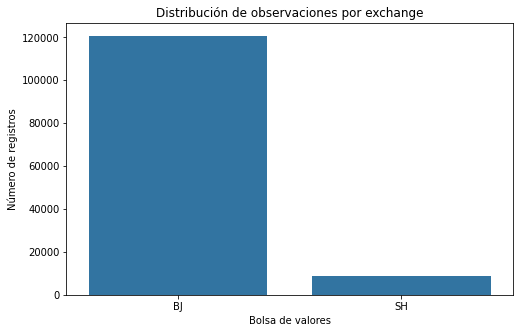

In [6]:
plt.figure(figsize=(8, 5))
import seaborn as sns
sns.countplot(
    data=df,
    x='exchange',
    order=df['exchange'].value_counts().index
)

plt.title("Distribución de observaciones por exchange")
plt.xlabel("Bolsa de valores")
plt.ylabel("Número de registros")

plt.show()

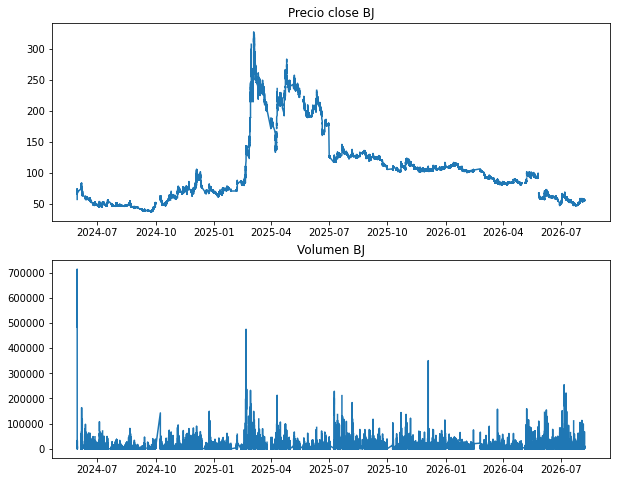

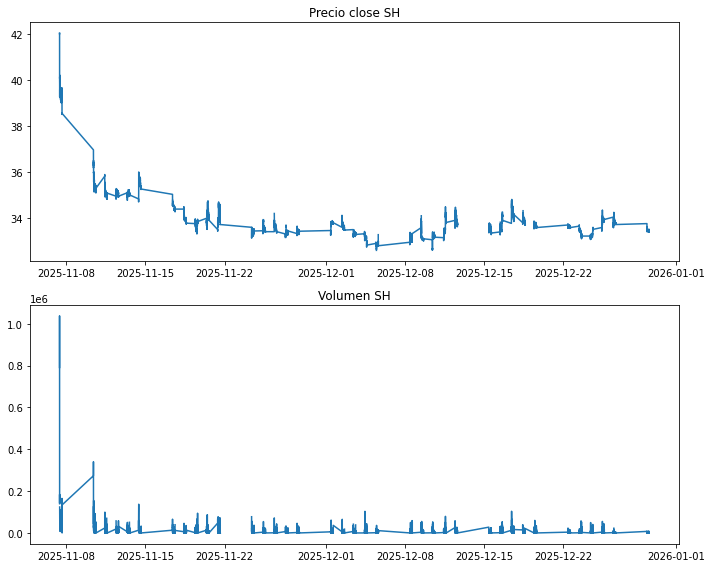

In [7]:
df1=df[df["exchange"]=="BJ"]
df2=df[df["exchange"]=="SH"]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(df1["timestamp"], df1["close"])
axes[0].set_title("Precio close BJ")

axes[1].plot(df1["timestamp"], df1["volume"])
axes[1].set_title("Volumen BJ")

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(df2["timestamp"], df2["close"])
axes[0].set_title("Precio close SH")

axes[1].plot(df2["timestamp"], df2["volume"])
axes[1].set_title("Volumen SH")

plt.tight_layout()
plt.show()

In [8]:
print(
    df.groupby('exchange')
    .agg(
        precio_medio=('close', 'mean'),
        volumen_medio=('volume', 'mean'),
        precio_mediano=('close', 'median')
    )
)
df['timestamp'] = pd.to_datetime(df['timestamp'])

cobertura = df.groupby('exchange').agg(
    fecha_inicio=('timestamp', 'min'),
    fecha_fin=('timestamp', 'max'),
    total_registros=('timestamp', 'count'),
)

display(cobertura)

          precio_medio  volumen_medio  precio_mediano
exchange                                             
BJ          104.616754    5316.739154       93.580000
SH           33.980369    6503.478641       33.689999


,fecha_inicio,fecha_fin,total_registros
exchange,,,
BJ,2024-05-30 09:30:00,2026-08-07 10:21:00,120647
SH,2025-11-07 09:30:00,2025-12-29 14:02:00,8931



Al analizar las fechas de inicio y fin de las observaciones, se observa que ambas bolsas presentan períodos de recopilación de datos muy diferentes.

La bolsa BJ contiene registros desde mayo de 2024 hasta agosto de 2026, mientras que SH únicamente presenta observaciones desde noviembre hasta diciembre de 2025.

Esta diferencia explica, al menos parcialmente, el desequilibrio en el número de registros. Por tanto, no podemos atribuirlo directamente a una menor actividad de la bolsa SH, ya que su período de representación en el conjunto de datos es considerablemente más corto.

Además, se observan diferencias en los niveles medios de precios y volúmenes. Estas diferencias deben tenerse en cuenta durante el análisis y el preprocesamiento, evitando aplicar transformaciones o imputaciones globales que puedan distorsionar las características de cada mercado.

In [34]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = df.sort_values('timestamp').reset_index(drop=True)

variables_continuas = ['open', 'high', 'low', 'close', 'volume', 'turnover']
variable_binaria = 'exchange_SH'

train_size = int(len(df) * 0.8)

df_train = df.iloc[:train_size].copy()
df_test = df.iloc[train_size:].copy()
df_limpio=df_train
print(f"Filas en Train: {len(df_train)} | Filas en Test: {len(df_test)}")


Filas en Train: 102840 | Filas en Test: 25710


#### Identificación y eliminación de registros duplicados

Se identificará la presencia de registros duplicados en el conjunto de datos. Posteriormente, se eliminarán los duplicados considerando las columnas exchange y timestamp como clave de identificación, conservando el último registro de cada combinación.

In [29]:
print("Duplicados",
      df.duplicated().sum())

df = df.drop_duplicates(
    subset=["exchange", "timestamp"],
    keep="last"
).copy()

Duplicados 0


#### Tratamiento de valores ausentes


Se eliminarán los registros que presenten valores ausentes en las variables esenciales para el análisis de precios (exchange, open, high, low y close). Para las variables volume y turnover, se sustituirán los valores ausentes por la mediana correspondiente a cada bolsa, evitando utilizar una única estadística global para ambos mercados.

In [30]:
df_limpio = df_limpio.dropna(
    subset=['exchange', 'open', 'high', 'low', 'close']
).copy()

for col in ['volume', 'turnover']:

    mediana_exchange = (
        df_limpio.groupby('exchange')[col]
        .transform('median')
    )

    df_limpio[col] = df_limpio[col].fillna(
        mediana_exchange
    )
    
print("Valores ausentes después del tratamiento:")
print(df_limpio.isnull().sum())

Valores ausentes después del tratamiento:
exchange     0
timestamp    0
open         0
high         0
low          0
close        0
volume       0
turnover     0
dtype: int64


#### Detección de inconsistencias en los precios OHLC

Se comprobará la coherencia de los precios de cada registro mediante las relaciones que deben cumplirse entre las variables `open`, `high`, `low` y `close`. En particular, el precio máximo (`high`) no debe ser inferior a ninguno de los demás precios, y el mínimo (`low`) no debe superarlos. Se identificarán y eliminarán los registros que incumplan estas condiciones.

In [31]:
condicion_invalida = (
    (df_limpio['high'] < df_limpio['low']) |
    (df_limpio['high'] < df_limpio['open']) |
    (df_limpio['high'] < df_limpio['close']) |
    (df_limpio['low'] > df_limpio['open']) |
    (df_limpio['low'] > df_limpio['close'])
)

inconsistencias = df_limpio[condicion_invalida]

print("Registros inconsistentes:", len(inconsistencias))

display(inconsistencias.head())
columnas_numericas = df.select_dtypes(include=['number']).columns

condicion_negativa = (
    (df_limpio[columnas_numericas] < 0).any(axis=1)
)

print("Registros con valores negativos:",
      condicion_negativa.sum())

df_limpio = df_limpio[~condicion_invalida & ~condicion_negativa].copy()

Registros inconsistentes: 0


,exchange,timestamp,open,high,low,close,volume,turnover


Registros con valores negativos: 0


#### Detección de valores atípicos mediante IQR y MAD

Se compararán los valores atípicos identificados mediante los tres métodos aplicados (IQR, MAD y distancia de Mahalanobis), analizando tanto la cantidad de observaciones detectadas por cada uno como el grado de coincidencia entre sus resultados. Para ello, se clasificará cada registro según el número de métodos que lo identifican como atípico, permitiendo distinguir las anomalías detectadas por un único método de aquellas que son identificadas por varios.

In [32]:
import numpy as np
import pandas as pd

variables = [
    'open',
    'high',
    'low',
    'close',
    'volume',
    'turnover'
]

df_outliers = df_limpio.copy()

# Convertir a numérico
df_outliers[variables] = df_outliers[variables].apply(
    pd.to_numeric, errors='coerce'
)

# Sustituir infinitos por ausentes
df_outliers[variables] = df_outliers[variables].replace(
    [np.inf, -np.inf], np.nan
)

def detectar_iqr(datos):
    resultados = pd.DataFrame(
        False,
        index=datos.index,
        columns=datos.columns
    )

    for columna in datos.columns:
        q1 = datos[columna].quantile(0.25)
        q3 = datos[columna].quantile(0.75)

        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        resultados[columna] = (
            (datos[columna] < limite_inferior) |
            (datos[columna] > limite_superior)
        )

    return resultados

df_outliers['outlier_iqr'] = False

for exchange, indices in df_outliers.groupby('exchange').groups.items():

    X = df_outliers.loc[indices, variables]

    resultados = detectar_iqr(X)

    df_outliers.loc[indices, 'outlier_iqr'] = (
        resultados.any(axis=1)
    )
    
def detectar_mad(datos, umbral=3.5):

    resultados = pd.DataFrame(
        False,
        index=datos.index,
        columns=datos.columns
    )

    for columna in datos.columns:

        mediana = datos[columna].median()

        mad = np.median(
            np.abs(datos[columna].dropna() - mediana)
        )

        if mad == 0:
            continue

        puntuacion = (
            0.6745 *
            np.abs(datos[columna] - mediana) / mad
        )

        resultados[columna] = puntuacion > umbral

    return resultados


In [33]:
from sklearn.preprocessing import RobustScaler
from sklearn.covariance import MinCovDet
from scipy.stats import chi2

df_outliers['dist_mahalanobis'] = np.nan
df_outliers['outlier_mahalanobis'] = False
df_outliers['outlier_mad'] = False

for exchange, indices in df_outliers.groupby('exchange').groups.items():

    X = df_outliers.loc[indices, variables]

    resultados_mad = detectar_mad(X)

    df_outliers.loc[indices, 'outlier_mad'] = (
        resultados_mad.any(axis=1)
    )

    if len(X) < 100:
        continue

    scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)

    modelo = MinCovDet(random_state=42)
    modelo.fit(X_scaled)

    # Distancia de Mahalanobis al cuadrado
    distancias = modelo.mahalanobis(X_scaled)

    # Umbral aproximado del 99 %
    umbral = chi2.ppf(0.99, df=len(variables))

    df_outliers.loc[X.index, 'dist_mahalanobis'] = distancias

    df_outliers.loc[X.index, 'outlier_mahalanobis'] = (
        distancias > umbral
    )
comparacion = pd.DataFrame({
    'IQR': df_outliers['outlier_iqr'],
    'MAD': df_outliers['outlier_mad'],
    'Mahalanobis': df_outliers['outlier_mahalanobis']
})

resumen = pd.DataFrame({
    'Método': comparacion.columns,
    'Cantidad': comparacion.sum().values,
    'Porcentaje': (
        comparacion.mean().values * 100
    ).round(2)
})

display(resumen)    
df_outliers['metodos_detectados'] = comparacion.sum(axis=1)

df_outliers['clasificacion'] = np.select(
    [
        df_outliers['metodos_detectados'] == 0,
        df_outliers['metodos_detectados'] == 1,
        df_outliers['metodos_detectados'] == 2,
        df_outliers['metodos_detectados'] == 3
    ],
    [
        'No detectado',
        'Detectado por un método',
        'Detectado por dos métodos',
        'Detectado por los tres métodos'
    ],
    default='Sin clasificar'
)

display(df_outliers['clasificacion'].value_counts())

/home/jennifer/venv/lib/python3.12/site-packages/sklearn/covariance/_robust_covariance.py:187: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-42.211463916453773 > -67.610539465866054). You may want to try with a higher value of support_fraction (current value: 0.501).
  warnings.warn(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/covariance/_robust_covariance.py:187: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-42.216239703022403 > -66.902128703744594). You may want to try with a higher value of support_fraction (current value: 0.501).
  warnings.warn(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/covariance/_robust_covariance.py:187: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-42.216239703022403 > -66.902128703744594). You may want to try with a higher value of support_fraction (current value: 0.501).
  warn

,Método,Cantidad,Porcentaje
0,IQR,19965,17.21
1,MAD,16891,14.56
2,Mahalanobis,51115,44.06


clasificacion
No detectado                      64346
Detectado por un método           30746
Detectado por los tres métodos    15389
Detectado por dos métodos          5529
Name: count, dtype: int64

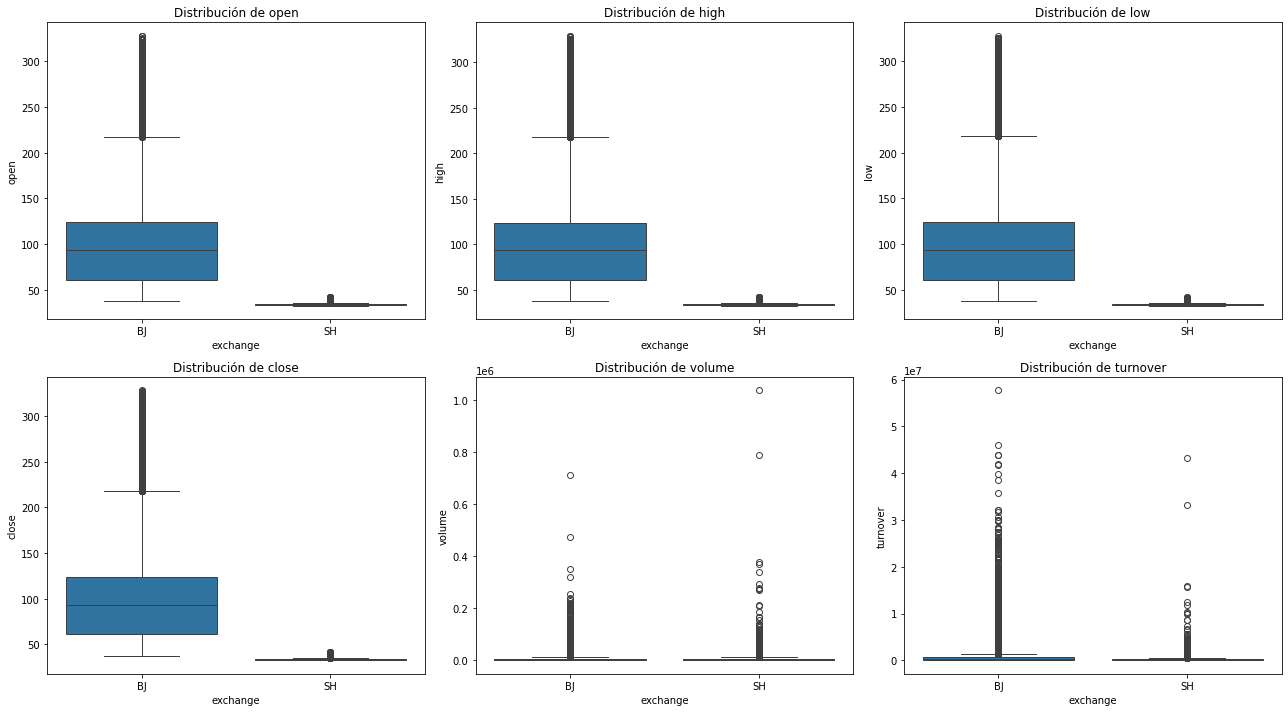

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, columna in zip(axes.flatten(), variables):

    sns.boxplot(
        data=df_outliers,
        x='exchange',
        y=columna,
        ax=ax
    )

    ax.set_title(f'Distribución de {columna}')

plt.tight_layout()
plt.show()

In [15]:
resultados_variables = []

for exchange, indices in df_outliers.groupby('exchange').groups.items():

    X = df_outliers.loc[indices, variables]

    iqr = detectar_iqr(X)
    mad = detectar_mad(X)

    for columna in variables:

        resultados_variables.append({
            'exchange': exchange,
            'variable': columna,
            'outliers_IQR': iqr[columna].sum(),
            'outliers_MAD': mad[columna].sum()
        })

resumen_variables = pd.DataFrame(resultados_variables)

display(resumen_variables)

,exchange,variable,outliers_IQR,outliers_MAD
0,BJ,open,8122,1427
1,BJ,high,8173,1468
2,BJ,low,8050,1382
3,BJ,close,8124,1423
4,BJ,volume,10150,10645
5,BJ,turnover,10470,12527
6,SH,open,722,477
7,SH,high,711,492
8,SH,low,762,476
9,SH,close,721,480


In [16]:
# Observaciones detectadas por los tres métodos
display(
    df_outliers[
        df_outliers['clasificacion'] ==
        'Detectado por los tres métodos'
    ][[ 'exchange', 'timestamp'] + variables].head(10)
)

# Observaciones detectadas exclusivamente por Mahalanobis
display(
    df_outliers[
        df_outliers['outlier_mahalanobis'] &
        ~df_outliers['outlier_iqr'] &
        ~df_outliers['outlier_mad']
    ][[ 'exchange', 'timestamp'] + variables].head(10)
)

,exchange,timestamp,open,high,low,close,volume,turnover
1,BJ,2024-05-30 09:31:00,57.000000,59.849998,57.000000,57.040001,714084.0,41769792.0
2,BJ,2024-05-30 09:32:00,57.040001,61.000000,57.040001,61.000000,318711.0,18763866.0
3,BJ,2024-05-30 09:33:00,61.000000,64.330002,61.000000,64.330002,158099.0,9916887.0
4,BJ,2024-05-30 09:34:00,64.330002,66.660004,64.330002,66.500000,169405.0,11110579.0
5,BJ,2024-05-30 09:35:00,66.500000,66.599998,63.000000,63.000000,202021.0,13369981.0
6,BJ,2024-05-30 09:36:00,63.000000,65.800003,60.990002,65.349998,106053.0,6622641.5
7,BJ,2024-05-30 09:37:00,65.349998,66.110001,64.000000,65.330002,132022.0,8705145.0
8,BJ,2024-05-30 09:38:00,65.330002,65.330002,63.000000,64.010002,64961.0,4130840.0
9,BJ,2024-05-30 09:39:00,64.010002,65.900002,64.000000,65.500000,65123.0,4235221.5
10,BJ,2024-05-30 09:40:00,65.500000,66.010002,65.389999,65.449997,76854.0,5066712.0


,exchange,timestamp,open,high,low,close,volume,turnover
31,BJ,2024-05-30 10:01:00,68.440002,68.440002,68.220001,68.400002,10392.0,710577.7500
39,BJ,2024-05-30 10:09:00,66.080002,67.000000,66.080002,67.000000,10950.0,728895.8750
44,BJ,2024-05-30 10:14:00,68.000000,69.500000,68.000000,69.489998,11221.0,773098.5000
45,BJ,2024-05-30 10:15:00,69.489998,69.750000,68.699997,69.489998,7783.0,539638.6875
46,BJ,2024-05-30 10:16:00,69.489998,69.489998,68.099998,68.099998,5511.0,379993.3750
47,BJ,2024-05-30 10:17:00,68.099998,68.599998,68.000000,68.599998,7800.0,531114.5625
48,BJ,2024-05-30 10:18:00,68.599998,69.389999,68.500000,68.900002,6826.0,470558.5625
49,BJ,2024-05-30 10:19:00,68.900002,69.300003,68.900002,69.019997,6600.0,456145.1875
50,BJ,2024-05-30 10:20:00,69.019997,69.279999,69.000000,69.180000,7499.0,518306.5000
51,BJ,2024-05-30 10:21:00,69.180000,69.269997,68.900002,68.900002,3164.0,218866.9375


Tras analizar los resultados obtenidos mediante los métodos IQR, MAD y distancia de Mahalanobis, se decide conservar las observaciones identificadas como atípicas. Esta decisión se fundamenta en que, en los datos financieros, los valores extremos pueden representar fluctuaciones reales del mercado y no necesariamente errores de registro. Por tanto, eliminarlos podría suponer una pérdida de información relevante. No obstante, se mantendrán identificados para tener en cuenta su posible influencia en las etapas posteriores del preprocesamiento y en el entrenamiento de los modelos.

La detección de valores atípicos no implica necesariamente su eliminación. La decisión dependerá de si representan errores de medición, registros anómalos o comportamientos reales del fenómeno estudiado.

La variable `exchange` representa la bolsa de valores y es de tipo categórico. Para facilitar su utilización en los algoritmos, se transformará mediante la técnica One-Hot Encoding, convirtiéndola en una variable numérica binaria. Se utilizará `drop_first=True` para evitar redundancia en la representación de las categorías.

In [21]:

df_codificado = pd.get_dummies(
    df_limpio,
    columns=['exchange'],
    dtype=int,
    drop_first=True
)

display(df_codificado.head())

,timestamp,open,high,low,close,volume,turnover,exchange_SH
1,2024-05-30 09:31:00,57.000000,59.849998,57.000000,57.040001,714084.0,41769792.0,0
2,2024-05-30 09:32:00,57.040001,61.000000,57.040001,61.000000,318711.0,18763866.0,0
3,2024-05-30 09:33:00,61.000000,64.330002,61.000000,64.330002,158099.0,9916887.0,0
4,2024-05-30 09:34:00,64.330002,66.660004,64.330002,66.500000,169405.0,11110579.0,0
5,2024-05-30 09:35:00,66.500000,66.599998,63.000000,63.000000,202021.0,13369981.0,0


Se aplicarán dos técnicas de escalado a las variables numéricas: Min-Max Scaling y estandarización mediante StandardScaler. La primera transforma los valores al intervalo [0,1], mientras que la segunda transforma los datos para obtener una media cercana a 0 y una desviación estándar cercana a 1. El objetivo es comparar ambas técnicas y observar cómo modifican la escala y distribución de los datos.

In [ ]:
scaler_minmax = MinMaxScaler()

variables = [
    'open', 'high', 'low', 'close',
    'volume', 'turnover'
]

X = df_codificado[variables].dropna().copy()
X_minmax = scaler_minmax.fit_transform(X)

df_minmax = pd.DataFrame(
    X_minmax,
    columns=variables,
    index=X.index
)

display(df_minmax.head())

,open,high,low,close,volume,turnover
0,0.082600,0.091875,0.082656,0.082735,0.688179,0.724149
1,0.082735,0.095752,0.082791,0.096141,0.307149,0.325303
2,0.096141,0.106979,0.096206,0.107414,0.152364,0.171926
3,0.107414,0.114835,0.107486,0.114760,0.163259,0.192620
4,0.114760,0.114632,0.102981,0.102911,0.194692,0.231791


In [24]:
scaler_standard = StandardScaler()

X_standard = scaler_standard.fit_transform(X)

df_standard = pd.DataFrame(
    X_standard,
    columns=variables,
    index=X.index
)

display(df_standard.head())

,open,high,low,close,volume,turnover
0,-0.807285,-0.761453,-0.806647,-0.806618,63.728282,28.749630
1,-0.806631,-0.742702,-0.805992,-0.741916,28.184015,12.673859
2,-0.741923,-0.688408,-0.741148,-0.687508,13.744901,6.491887
3,-0.687510,-0.650419,-0.686620,-0.652053,14.761317,7.325999
4,-0.652051,-0.651397,-0.708398,-0.709239,17.693515,8.904793


Se representará la distribución de la variable `volume` antes y después de aplicar ambas técnicas de escalado. Esto permitirá observar cómo se modifica su escala y comprobar si se conserva la forma general de la distribución.

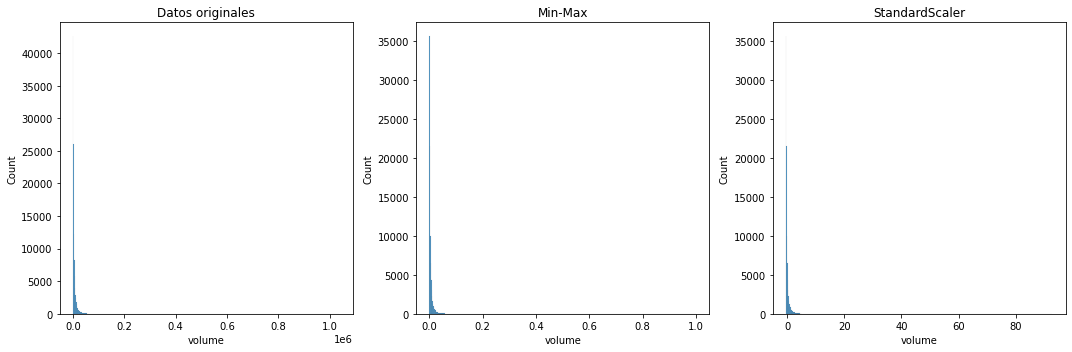

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(df_limpio['volume'], ax=axes[0])
axes[0].set_title("Datos originales")

sns.histplot(df_minmax['volume'], ax=axes[1])
axes[1].set_title("Min-Max")

sns.histplot(df_standard['volume'], ax=axes[2])
axes[2].set_title("StandardScaler")

plt.tight_layout()
plt.show()

Se observa que StandardScaler conserva visualmente una forma de distribución más semejante a la de los datos originales, aunque modifica su escala y centra los valores alrededor de cero. Min-Max Scaling también conserva el orden y la forma relativa de la distribución, pero transforma los valores al intervalo [0,1]. Por tanto, la elección de la técnica dependerá de los requisitos del algoritmo que se vaya a utilizar.